In [79]:
%pip install matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\ayaan\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [80]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [81]:
# Load cleaned Netflix dataset from Task 1

df = pd.read_csv(
    "../Task_1_Data_Cleaning/output/Netflix_Cleaned.csv"
)

# Display first 5 records

df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [82]:
# Check dataset information

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (8790, 10)

Column Names:
['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8790 non-null   str  
 1   type          8790 non-null   str  
 2   title         8790 non-null   str  
 3   director      8790 non-null   str  
 4   country       8790 non-null   str  
 5   date_added    8790 non-null   str  
 6   release_year  8790 non-null   int64
 7   rating        8790 non-null   str  
 8   duration      8790 non-null   str  
 9   listed_in     8790 non-null   str  
dtypes: int64(1), str(9)
memory usage: 686.8 KB


In [83]:
# Count Movies and TV Shows

content_counts = df["type"].value_counts()

print("Netflix Content Distribution:")
print(content_counts)

print("\nTotal Movies:", content_counts["Movie"])
print("Total TV Shows:", content_counts["TV Show"])

Netflix Content Distribution:
type
Movie      6126
TV Show    2664
Name: count, dtype: int64

Total Movies: 6126
Total TV Shows: 2664


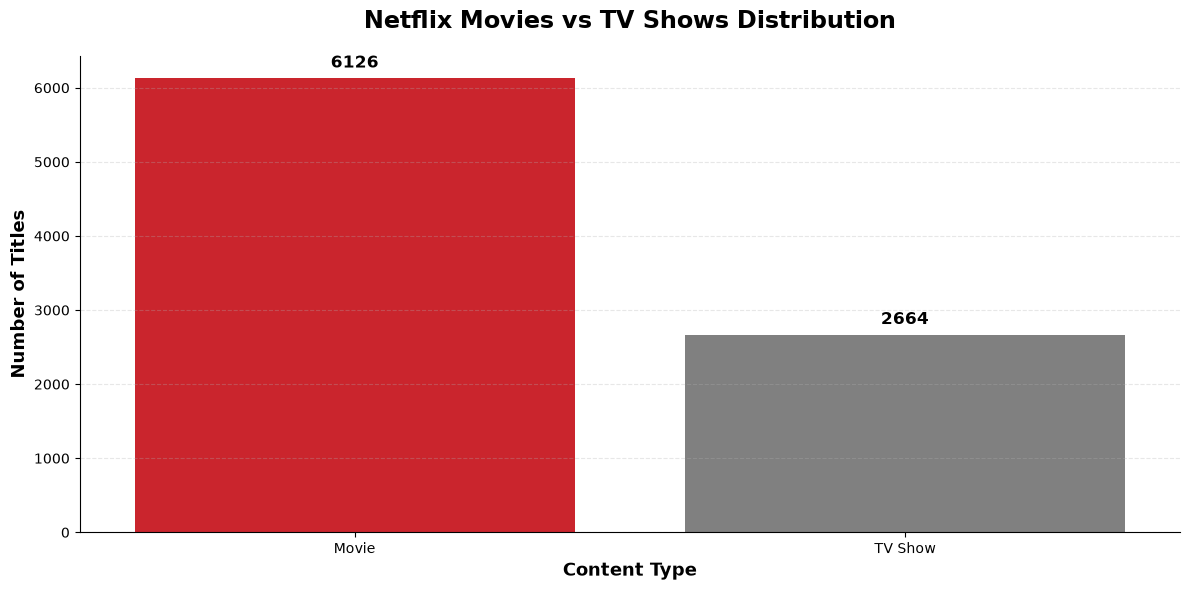

In [114]:
# Netflix Movies vs TV Shows Distribution

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate content counts
content_counts = df["type"].value_counts()

# Define colors
colors = ["#E50914", "#808080"]

# Create figure
plt.figure(figsize=(12, 6))

# Create bar chart
ax = sns.barplot(
    x=content_counts.index,
    y=content_counts.values,
    hue=content_counts.index,
    palette={
        "Movie": "#E50914",
        "TV Show": "#808080"
    },
    legend=False
)

# Add values above bars
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        padding=5,
        fontsize=12,
        fontweight="bold"
    )

# Chart title and labels
plt.title(
    "Netflix Movies vs TV Shows Distribution",
    fontsize=17,
    fontweight="bold",
    pad=20
)

plt.xlabel("Content Type", fontsize=13, fontweight="bold")
plt.ylabel("Number of Titles", fontsize=13, fontweight="bold")

# Styling
plt.grid(axis="y", linestyle="--", alpha=0.3)
sns.despine()
plt.tight_layout()

# Display chart
plt.show()

In [85]:
# Calculate content percentages

content_percentages = (
    df["type"].value_counts(normalize=True) * 100
)

print("Content Percentage Distribution:")
print(content_percentages)

Content Percentage Distribution:
type
Movie      69.692833
TV Show    30.307167
Name: proportion, dtype: float64


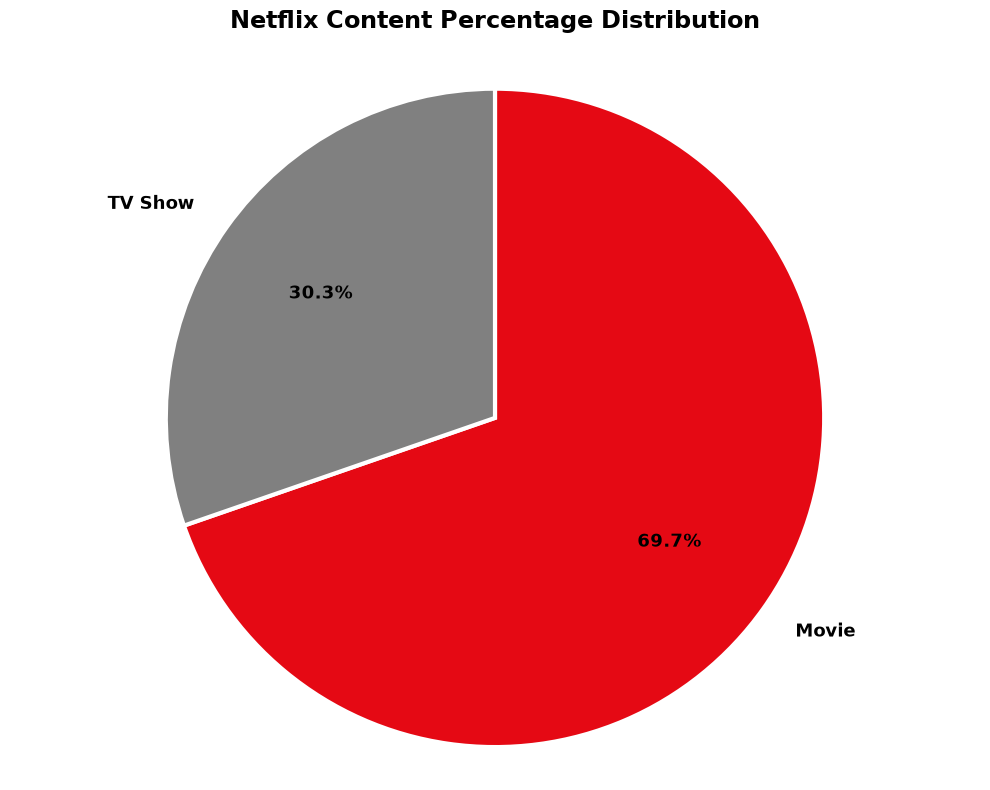

In [115]:
# Netflix Content Percentage Distribution

import matplotlib.pyplot as plt

# Calculate content counts
content_counts = df["type"].value_counts()

# Netflix theme colors
colors = ["#E50914", "#808080"]

# Create figure
plt.figure(figsize=(10, 8))

# Create pie chart
plt.pie(
    content_counts.values,
    labels=content_counts.index,
    colors=colors,
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
    pctdistance=0.65,
    labeldistance=1.12,
    textprops={
        "fontsize": 13,
        "fontweight": "bold"
    },
    wedgeprops={
        "edgecolor": "white",
        "linewidth": 3
    }
)

# Chart title
plt.title(
    "Netflix Content Percentage Distribution",
    fontsize=17,
    fontweight="bold",
    pad=20
)

# Keep pie chart circular
plt.axis("equal")

plt.tight_layout()
plt.show()

In [87]:
# Convert date_added column into datetime format

df["date_added_date"] = pd.to_datetime(
    df["date_added"],
    format="%m/%d/%Y",
    errors="coerce"
)

print("Date conversion completed!")

print("\nMissing Dates After Conversion:",
      df["date_added_date"].isnull().sum())

df[["title", "date_added", "date_added_date"]].head()

Date conversion completed!

Missing Dates After Conversion: 0


,title,date_added,date_added_date
0,Dick Johnson Is Dead,9/25/2021,2021-09-25
1,Ganglands,9/24/2021,2021-09-24
2,Midnight Mass,9/24/2021,2021-09-24
3,Confessions of an Invisible Girl,9/22/2021,2021-09-22
4,Sankofa,9/24/2021,2021-09-24


In [88]:
# Extract year from date_added

df["year_added"] = df["date_added_date"].dt.year

print("Year-wise Content Addition:")
print(df["year_added"].value_counts().sort_index())

Year-wise Content Addition:
year_added
2008       2
2009       2
2010       1
2011      13
2012       3
2013      11
2014      24
2015      82
2016     426
2017    1185
2018    1648
2019    2016
2020    1879
2021    1498
Name: count, dtype: int64


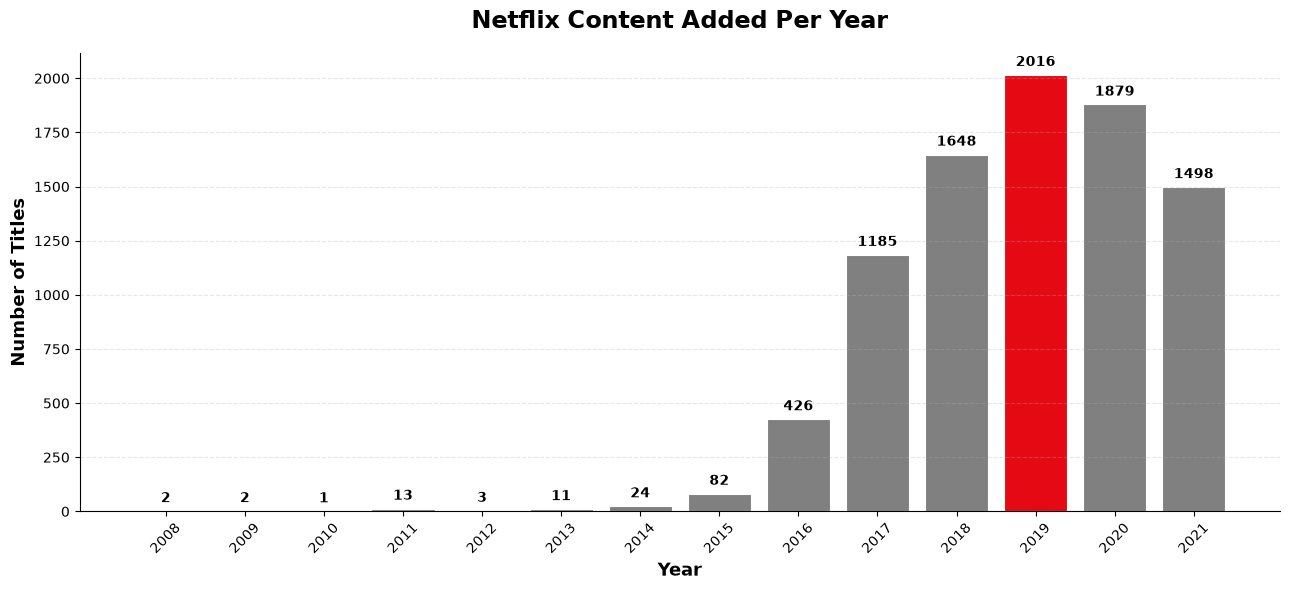

Peak Year: 2019 with 2016 titles added.


In [116]:
# Netflix Content Added Per Year

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Convert date_added into datetime format
df["date_added"] = pd.to_datetime(
    df["date_added"],
    format="%m/%d/%Y",
    errors="coerce"
)

# Extract year from date_added
df["year_added"] = df["date_added"].dt.year

# Calculate yearly content additions
year_counts = df["year_added"].value_counts().sort_index()

# Find the year with maximum content additions
peak_year = year_counts.idxmax()

# Assign colors: Red for peak year, Grey for others
colors = [
    "#E50914" if year == peak_year else "#808080"
    for year in year_counts.index
]

# Create figure
plt.figure(figsize=(13, 6))

# Create bar chart
bars = plt.bar(
    year_counts.index.astype(str),
    year_counts.values,
    color=colors,
    edgecolor="white",
    linewidth=0.8
)

# Add values above bars
plt.bar_label(
    bars,
    padding=4,
    fontsize=10,
    fontweight="bold"
)

# Title and labels
plt.title(
    "Netflix Content Added Per Year",
    fontsize=17,
    fontweight="bold",
    pad=18
)

plt.xlabel("Year", fontsize=13, fontweight="bold")
plt.ylabel("Number of Titles", fontsize=13, fontweight="bold")

# Styling
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.xticks(rotation=45)
sns.despine()

plt.tight_layout()
plt.show()

# Display peak year
print(
    f"Peak Year: {peak_year} "
    f"with {year_counts.max()} titles added."
)

In [90]:
# Movies vs TV Shows added each year

yearly_content = df.groupby(
    ["year_added", "type"]
).size().unstack(fill_value=0)

print("Year-wise Movies vs TV Shows:")
display(yearly_content)

Year-wise Movies vs TV Shows:


type,Movie,TV Show
year_added,,
2008,1,1
2009,2,0
2010,1,0
2011,13,0
2012,3,0
2013,6,5
2014,19,5
2015,56,26
2016,251,175


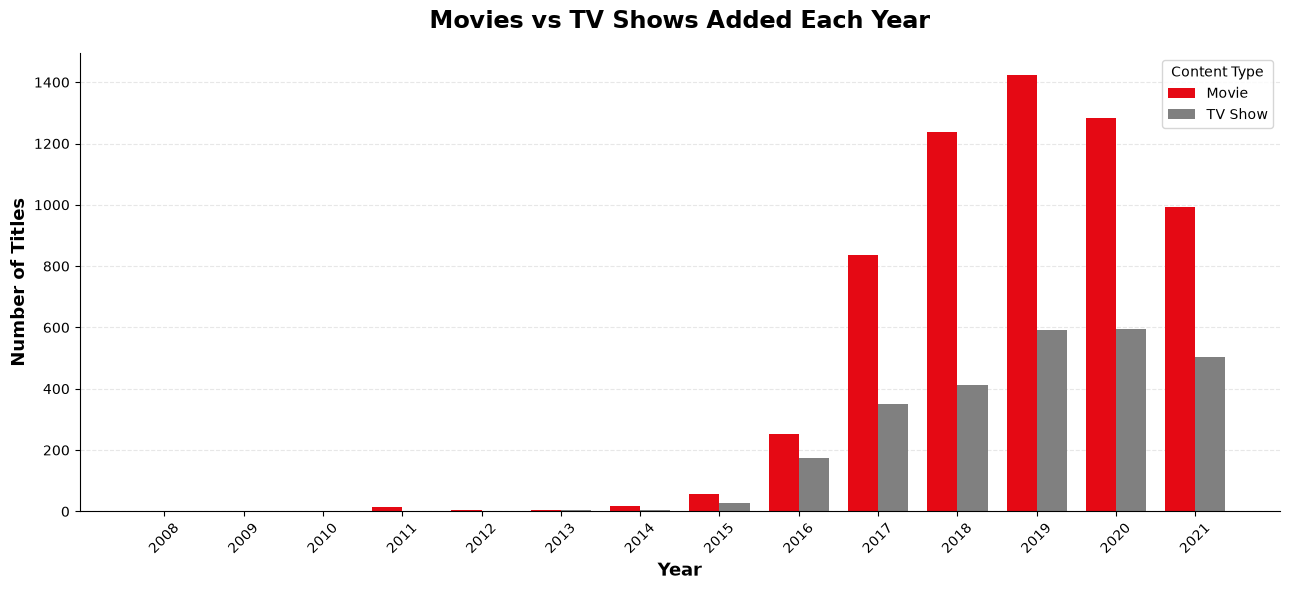

In [117]:
# Movies vs TV Shows Added Each Year

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Convert date_added into datetime
df["date_added"] = pd.to_datetime(
    df["date_added"],
    format="%m/%d/%Y",
    errors="coerce"
)

# Extract year
df["year_added"] = df["date_added"].dt.year

# Calculate Movies and TV Shows added each year
year_type_counts = (
    df.dropna(subset=["year_added"])
    .groupby(["year_added", "type"])
    .size()
    .unstack(fill_value=0)
    .sort_index()
)

# Prepare chart data
years = year_type_counts.index.astype(int).astype(str)
x = np.arange(len(years))
width = 0.38

# Create figure
fig, ax = plt.subplots(figsize=(13, 6))

# Movie bars
movie_bars = ax.bar(
    x - width / 2,
    year_type_counts["Movie"],
    width,
    label="Movie",
    color="#E50914"
)

# TV Show bars
tv_bars = ax.bar(
    x + width / 2,
    year_type_counts["TV Show"],
    width,
    label="TV Show",
    color="#808080"
)

# Chart title and labels
ax.set_title(
    "Movies vs TV Shows Added Each Year",
    fontsize=17,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Year", fontsize=13, fontweight="bold")
ax.set_ylabel("Number of Titles", fontsize=13, fontweight="bold")

# X-axis formatting
ax.set_xticks(x)
ax.set_xticklabels(years, rotation=45)

# Add legend
ax.legend(
    title="Content Type",
    frameon=True
)

# Grid styling
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

# Remove extra borders
sns.despine()

plt.tight_layout()
plt.show()

In [92]:
# Top 10 content producing countries

country_counts = (
    df["country"]
    .str.split(", ")
    .explode()
    .value_counts()
    .head(10)
)

print("Top 10 Content Producing Countries:")
display(country_counts)

Top 10 Content Producing Countries:


country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Unknown            287
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Name: count, dtype: int64

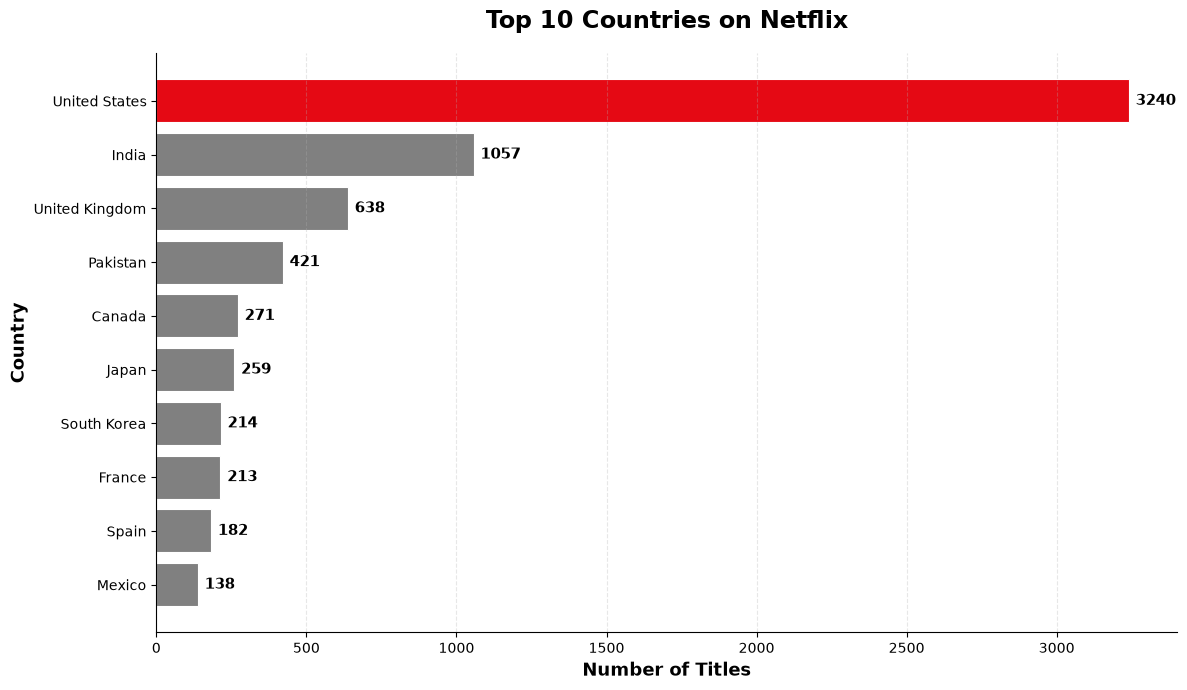

In [118]:
# Top 10 Countries on Netflix

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate top 10 countries
country_counts = (
    df[df["country"] != "Unknown"]["country"]
    .value_counts()
    .head(10)
)

# Netflix theme colors
colors = [
    "#E50914" if country == country_counts.index[0] else "#808080"
    for country in country_counts.index
]

# Create figure
plt.figure(figsize=(12, 7))

# Create horizontal bar chart
bars = plt.barh(
    country_counts.index,
    country_counts.values,
    color=colors,
    edgecolor="white",
    linewidth=0.8
)

# Display highest country at the top
plt.gca().invert_yaxis()

# Add values at the end of bars
plt.bar_label(
    bars,
    padding=5,
    fontsize=11,
    fontweight="bold"
)

# Title and labels
plt.title(
    "Top 10 Countries on Netflix",
    fontsize=17,
    fontweight="bold",
    pad=18
)

plt.xlabel("Number of Titles", fontsize=13, fontweight="bold")
plt.ylabel("Country", fontsize=13, fontweight="bold")

# Styling
plt.grid(axis="x", linestyle="--", alpha=0.3)
sns.despine()

plt.tight_layout()
plt.show()

In [94]:
# Movies vs TV Shows by Top 10 Countries

top_countries = country_counts.drop(
    "Unknown", errors="ignore"
).index

country_type = df.assign(
    country=df["country"].str.split(", ")
).explode("country")

country_type = country_type[
    country_type["country"].isin(top_countries)
]

country_type_counts = pd.crosstab(
    country_type["country"],
    country_type["type"]
)

display(country_type_counts)

type,Movie,TV Show
country,,
Canada,187,84
France,148,65
India,976,81
Japan,87,172
Pakistan,71,350
South Korea,49,165
Spain,129,53
United Kingdom,387,251
United States,2395,845


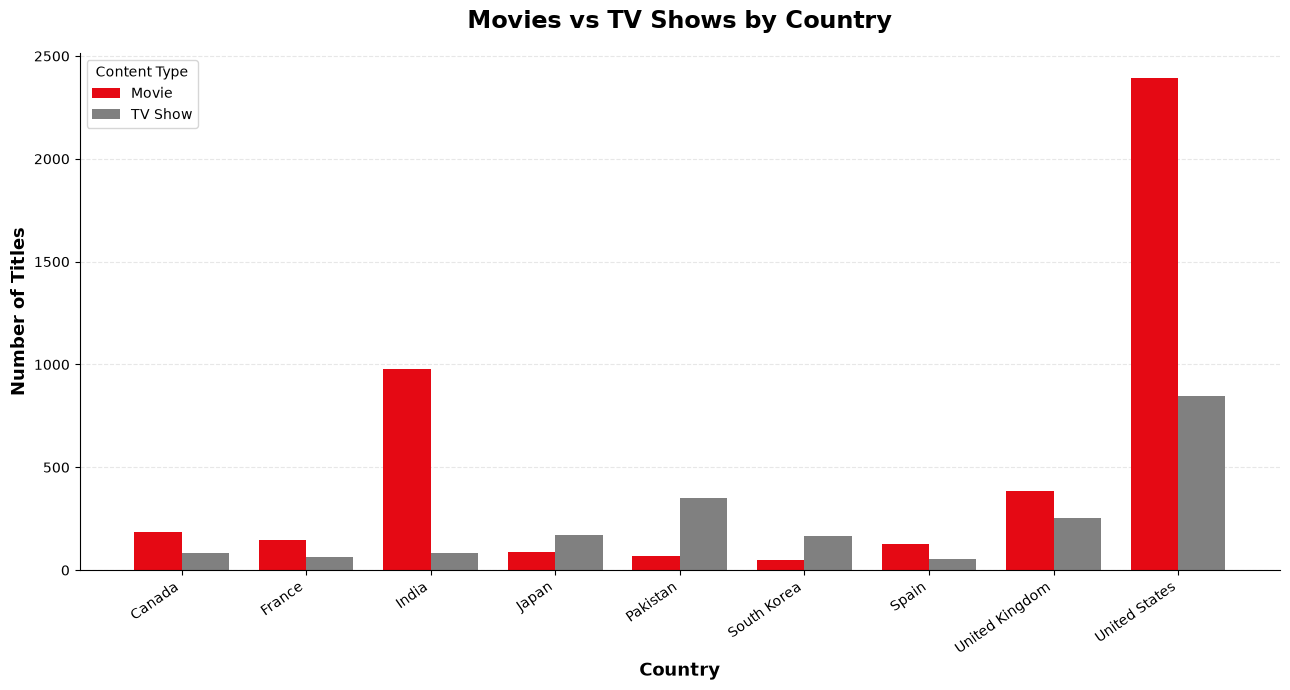

In [119]:
# Movies vs TV Shows by Country

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Prepare country-wise content data
plot_data = country_type_counts.sort_index()

# X-axis positions
countries = plot_data.index
x = np.arange(len(countries))
width = 0.38

# Create figure
fig, ax = plt.subplots(figsize=(13, 7))

# Movie bars
movie_bars = ax.bar(
    x - width / 2,
    plot_data["Movie"],
    width,
    label="Movie",
    color="#E50914"
)

# TV Show bars
tv_bars = ax.bar(
    x + width / 2,
    plot_data["TV Show"],
    width,
    label="TV Show",
    color="#808080"
)

# Title and labels
ax.set_title(
    "Movies vs TV Shows by Country",
    fontsize=17,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Country", fontsize=13, fontweight="bold")
ax.set_ylabel("Number of Titles", fontsize=13, fontweight="bold")

# X-axis formatting
ax.set_xticks(x)
ax.set_xticklabels(countries, rotation=35, ha="right")

# Legend
ax.legend(
    title="Content Type",
    frameon=True
)

# Grid and styling
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

sns.despine()
plt.tight_layout()
plt.show()

In [96]:
# Analyze Netflix Rating Distribution

rating_counts = df["rating"].value_counts()

print("Netflix Rating Distribution:")
display(rating_counts)

Netflix Rating Distribution:


rating
TV-MA       3205
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64

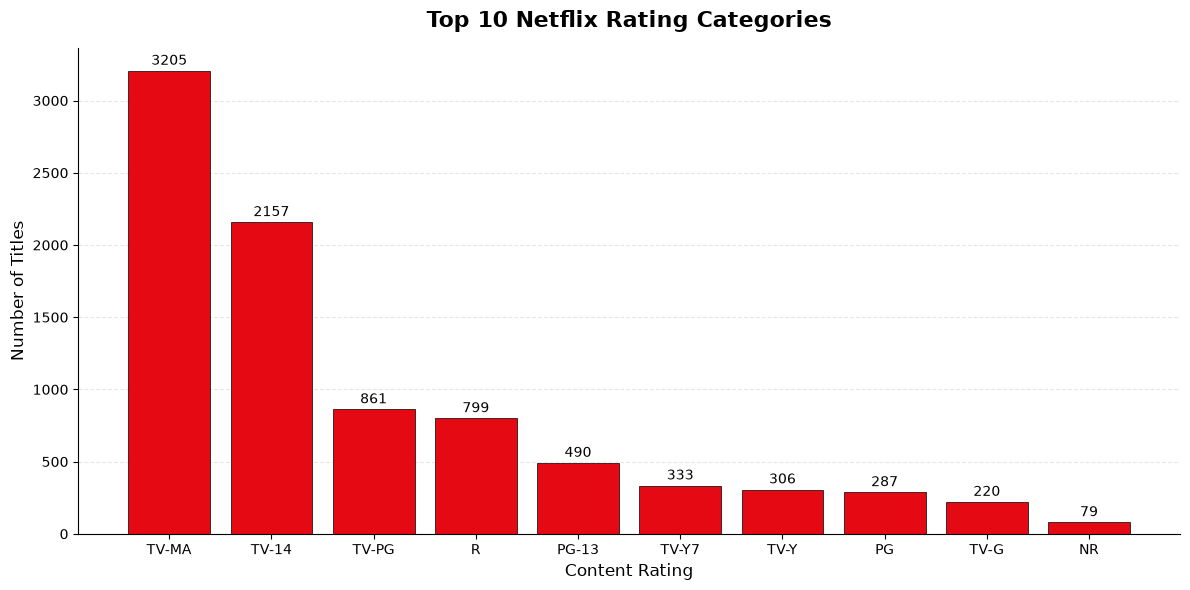

In [120]:
# Top 10 Netflix Rating Categories

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate top 10 ratings
top_ratings = df["rating"].value_counts().head(10)

# Create figure
plt.figure(figsize=(12, 6))

# Create bar chart
bars = plt.bar(
    top_ratings.index,
    top_ratings.values,
    color="#E50914",
    edgecolor="black",
    linewidth=0.5
)

# Add values above bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 20,
        f"{int(height)}",
        ha="center",
        va="bottom",
        fontsize=10
    )

# Title and labels
plt.title(
    "Top 10 Netflix Rating Categories",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Content Rating", fontsize=12)
plt.ylabel("Number of Titles", fontsize=12)

# Styling
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.gca().set_axisbelow(True)

sns.despine()
plt.tight_layout()
plt.show()

In [98]:
# Analyze duration of Movies and TV Shows

print("Duration Examples:")
display(df[["title", "type", "duration"]].head(10))

# Separate Movie and TV Show durations

movie_duration = df[df["type"] == "Movie"]["duration"]
tv_duration = df[df["type"] == "TV Show"]["duration"]

print("\nMovie Duration Examples:")
print(movie_duration.head())

print("\nTV Show Duration Examples:")
print(tv_duration.head())

Duration Examples:


,title,type,duration
0,Dick Johnson Is Dead,Movie,90 min
1,Ganglands,TV Show,1 Season
2,Midnight Mass,TV Show,1 Season
3,Confessions of an Invisible Girl,Movie,91 min
4,Sankofa,Movie,125 min
5,The Great British Baking Show,TV Show,9 Seasons
6,The Starling,Movie,104 min
7,Motu Patlu in the Game of Zones,Movie,87 min
8,Je Suis Karl,Movie,127 min
9,Motu Patlu in Wonderland,Movie,76 min



Movie Duration Examples:
0     90 min
3     91 min
4    125 min
6    104 min
7     87 min
Name: duration, dtype: str

TV Show Duration Examples:
1      1 Season
2      1 Season
5     9 Seasons
17     1 Season
18     1 Season
Name: duration, dtype: str


In [99]:
# Extract numeric duration values

df["duration_numeric"] = df["duration"].str.extract(
    r"(\d+)"
).astype(float)

# Average movie duration

avg_movie_duration = df[
    df["type"] == "Movie"
]["duration_numeric"].mean()

print("Average Movie Duration:", round(avg_movie_duration, 2), "minutes")

Average Movie Duration: 99.58 minutes


In [100]:
# Calculate average number of seasons for TV Shows

avg_tv_seasons = df[
    df["type"] == "TV Show"
]["duration_numeric"].mean()

print(
    "Average TV Show Seasons:",
    round(avg_tv_seasons, 2),
    "seasons"
)

Average TV Show Seasons: 1.75 seasons


In [101]:
# Analyze TV Show Seasons Distribution

tv_seasons = df[df["type"] == "TV Show"].copy()

tv_seasons["seasons"] = (
    tv_seasons["duration_numeric"].astype(int)
)

season_counts = tv_seasons["seasons"].value_counts().sort_index()

print("TV Show Seasons Distribution:")
print(season_counts)

TV Show Seasons Distribution:
seasons
1     1791
2      421
3      198
4       94
5       64
6       33
7       23
8       17
9        9
10       6
11       1
12       2
13       2
15       2
17       1
Name: count, dtype: int64


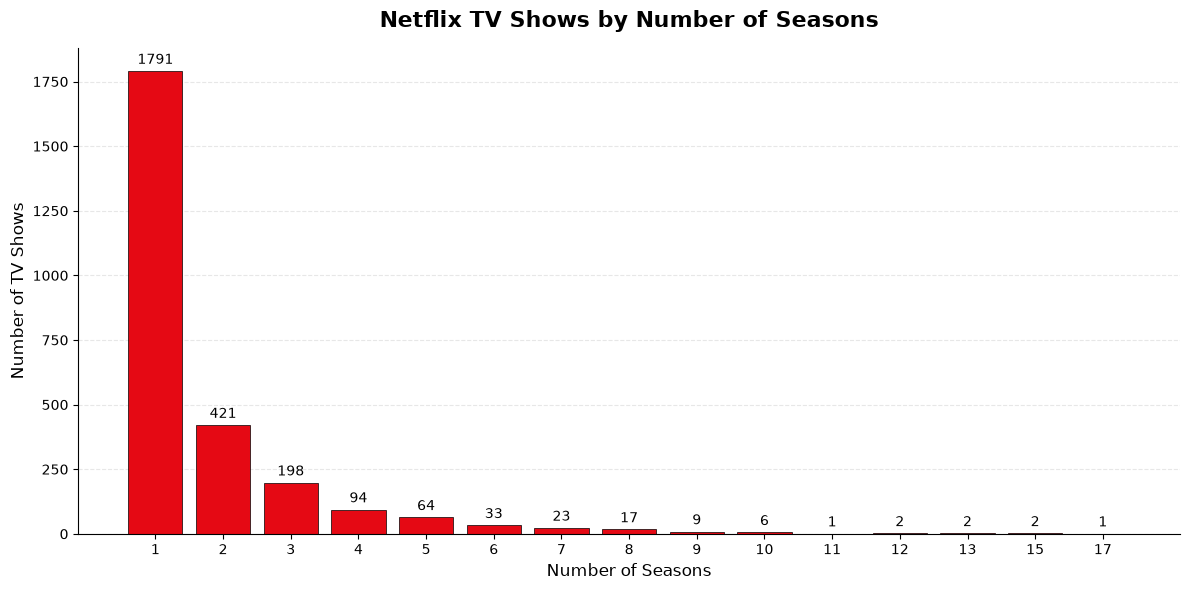

In [121]:
# Netflix TV Shows by Number of Seasons

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Filter TV Shows
tv_shows = df[df["type"] == "TV Show"].copy()

# Extract number of seasons
season_counts = tv_shows["duration"].value_counts()

# Sort seasons numerically
season_counts.index = season_counts.index.str.extract(r"(\d+)")[0].astype(int)
season_counts = season_counts.groupby(level=0).sum().sort_index()

# Create figure
plt.figure(figsize=(12, 6))

# Netflix Red bar chart
bars = plt.bar(
    season_counts.index.astype(str),
    season_counts.values,
    color="#E50914",
    edgecolor="black",
    linewidth=0.5
)

# Add values above bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 15,
        f"{int(height)}",
        ha="center",
        va="bottom",
        fontsize=10
    )

# Title and labels
plt.title(
    "Netflix TV Shows by Number of Seasons",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Number of Seasons", fontsize=12)
plt.ylabel("Number of TV Shows", fontsize=12)

# Styling
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.gca().set_axisbelow(True)

sns.despine()
plt.tight_layout()
plt.show()

In [103]:
# Find Top 10 TV Shows with Maximum Seasons

top_10_shows = tv_seasons[
    ["title", "seasons"]
].sort_values(
    by="seasons",
    ascending=False
).head(10)

print("Top 10 Longest-Running Netflix TV Shows:")
display(top_10_shows)

Top 10 Longest-Running Netflix TV Shows:


,title,seasons
6697,Grey's Anatomy,17
1971,Supernatural,15
7987,NCIS,15
7816,COMEDIANS of the world,13
6884,Heartland,13
8024,Trailer Park Boys,12
8164,Criminal Minds,12
8391,Cheers,11
7018,LEGO Ninjago: Masters of Spinjitzu,10
8311,Danger Mouse: Classic Collection,10


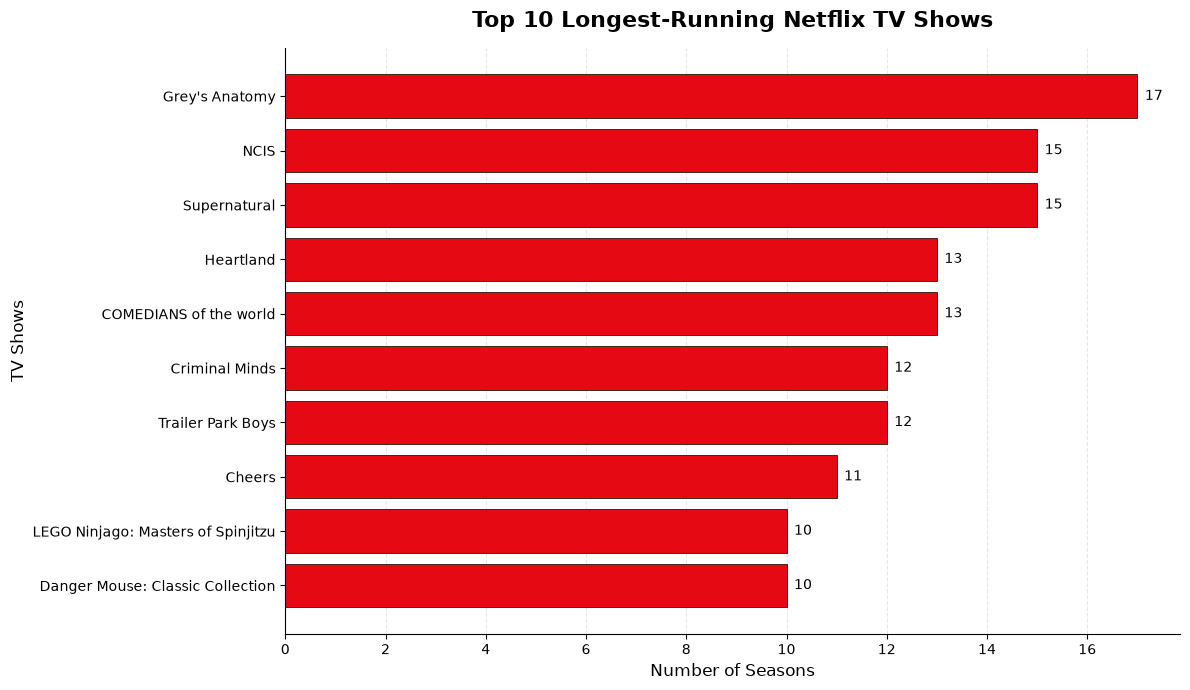

In [122]:
# Top 10 Longest-Running Netflix TV Shows

import matplotlib.pyplot as plt
import seaborn as sns

# Get TV Shows
tv_shows = df[df["type"] == "TV Show"].copy()

# Extract number of seasons
tv_shows["seasons"] = (
    tv_shows["duration"]
    .str.extract(r"(\d+)")
    .astype(int)
)

# Get top 10 longest-running shows
top_10_shows = (
    tv_shows[["title", "seasons"]]
    .sort_values("seasons", ascending=False)
    .head(10)
    .sort_values("seasons", ascending=True)
)

# Create figure
plt.figure(figsize=(12, 7))

# Horizontal bar chart
bars = plt.barh(
    top_10_shows["title"],
    top_10_shows["seasons"],
    color="#E50914",
    edgecolor="black",
    linewidth=0.5
)

# Add season values
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.15,
        bar.get_y() + bar.get_height() / 2,
        f"{int(width)}",
        va="center",
        fontsize=10
    )

# Title and labels
plt.title(
    "Top 10 Longest-Running Netflix TV Shows",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Number of Seasons", fontsize=12)
plt.ylabel("TV Shows", fontsize=12)

# Styling
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.gca().set_axisbelow(True)

sns.despine()
plt.tight_layout()
plt.show()

In [105]:
# Analyze Movie Duration Distribution

movies = df[df["type"] == "Movie"].copy()

movies["duration_category"] = pd.cut(
    movies["duration_numeric"],
    bins=[0, 60, 90, 120, 150, float("inf")],
    labels=[
        "Under 60 min",
        "60-90 min",
        "90-120 min",
        "120-150 min",
        "150+ min"
    ]
)

duration_counts = movies["duration_category"].value_counts().sort_index()

print("Movie Duration Distribution:")
print(duration_counts)

Movie Duration Distribution:
duration_category
Under 60 min     486
60-90 min       1503
90-120 min      2995
120-150 min      897
150+ min         245
Name: count, dtype: int64


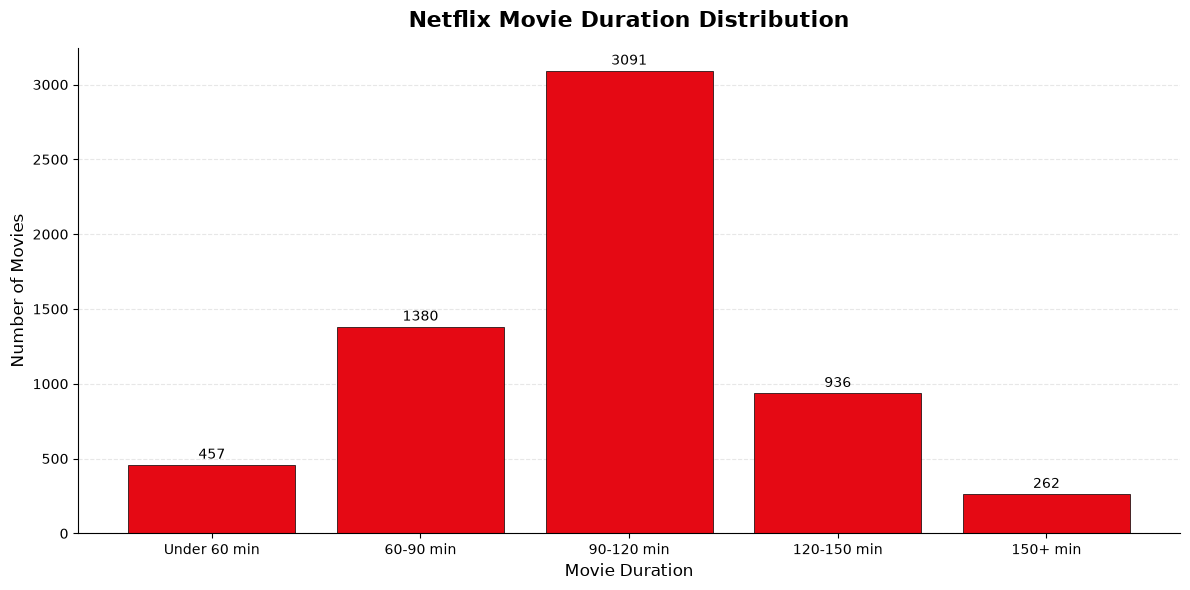

In [124]:
# Netflix Movie Duration Distribution

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Filter only Movies
movies = df[df["type"] == "Movie"].copy()

# Extract duration in minutes
movies["duration_minutes"] = pd.to_numeric(
    movies["duration"].str.extract(r"(\d+)")[0],
    errors="coerce"
)

# Create duration categories
bins = [0, 60, 90, 120, 150, float("inf")]

labels = [
    "Under 60 min",
    "60-90 min",
    "90-120 min",
    "120-150 min",
    "150+ min"
]

movies["duration_category"] = pd.cut(
    movies["duration_minutes"],
    bins=bins,
    labels=labels,
    right=False
)

# Count movies in each category
movie_duration_counts = (
    movies["duration_category"]
    .value_counts()
    .reindex(labels, fill_value=0)
)

# Create figure
plt.figure(figsize=(12, 6))

# Netflix Red bar chart
bars = plt.bar(
    movie_duration_counts.index,
    movie_duration_counts.values,
    color="#E50914",
    edgecolor="black",
    linewidth=0.5
)

# Add values above bars
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 20,
        f"{int(height)}",
        ha="center",
        va="bottom",
        fontsize=10
    )

# Title and labels
plt.title(
    "Netflix Movie Duration Distribution",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Movie Duration", fontsize=12)
plt.ylabel("Number of Movies", fontsize=12)

# Styling
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.gca().set_axisbelow(True)

sns.despine()
plt.tight_layout()
plt.show()

In [107]:
# Analyze Most Common Netflix Genres

from collections import Counter

genre_list = []

for genres in df["listed_in"]:
    genre_list.extend(
        [genre.strip() for genre in genres.split(",")]
    )

genre_counts = pd.Series(
    Counter(genre_list)
).sort_values(ascending=False).head(10)

print("Top 10 Netflix Genres:")
print(genre_counts)

Top 10 Netflix Genres:
International Movies        2752
Dramas                      2426
Comedies                    1674
International TV Shows      1349
Documentaries                869
Action & Adventure           859
TV Dramas                    762
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
dtype: int64


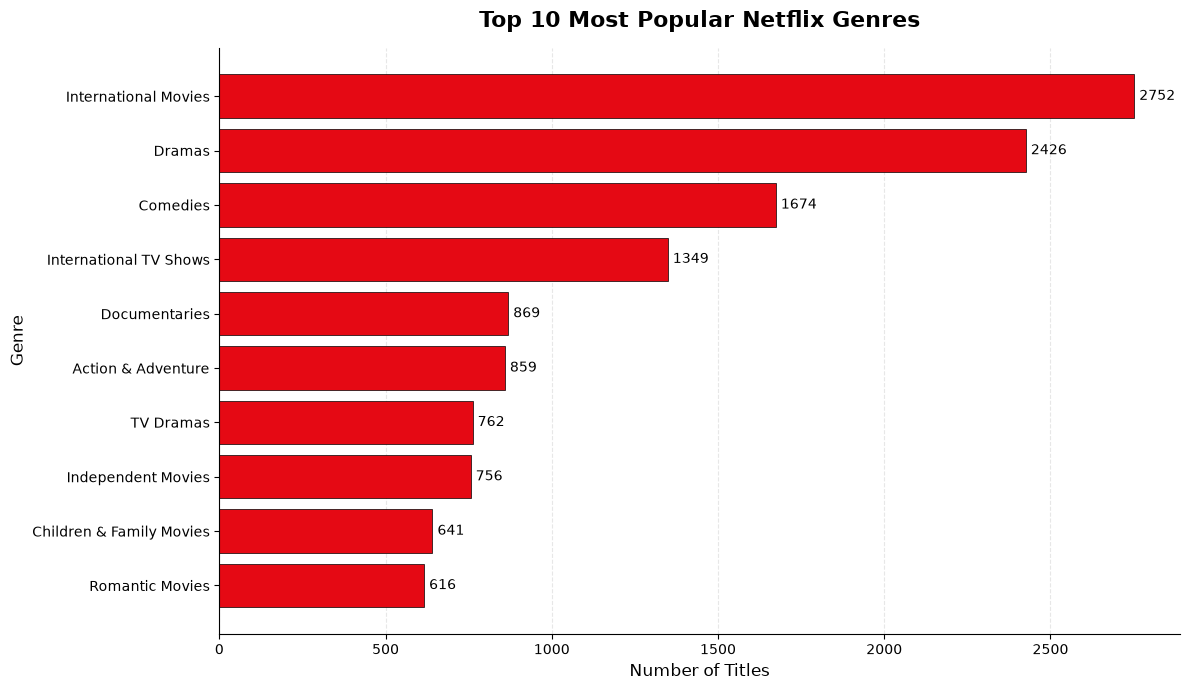

In [125]:
# Top 10 Most Popular Netflix Genres

import matplotlib.pyplot as plt
import seaborn as sns

# Extract and count genres
genre_counts = (
    df["listed_in"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
    .value_counts()
    .head(10)
)

# Reverse order for horizontal chart
top_genres = genre_counts.sort_values(ascending=True)

# Create figure
plt.figure(figsize=(12, 7))

# Netflix Red horizontal bar chart
bars = plt.barh(
    top_genres.index,
    top_genres.values,
    color="#E50914",
    edgecolor="black",
    linewidth=0.5
)

# Add values at the end of bars
for bar in bars:
    width = bar.get_width()

    plt.text(
        width + 15,
        bar.get_y() + bar.get_height() / 2,
        f"{int(width)}",
        va="center",
        fontsize=10
    )

# Title and labels
plt.title(
    "Top 10 Most Popular Netflix Genres",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Number of Titles", fontsize=12)
plt.ylabel("Genre", fontsize=12)

# Styling
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.gca().set_axisbelow(True)

sns.despine()
plt.tight_layout()
plt.show()

In [109]:
# Extract month from date_added

df["month_added"] = df["date_added_date"].dt.month

month_counts = df["month_added"].value_counts().sort_index()

print("Monthly Content Addition:")
print(month_counts)

Monthly Content Addition:
month_added
1     737
2     562
3     741
4     763
5     632
6     728
7     827
8     754
9     769
10    760
11    705
12    812
Name: count, dtype: int64


In [110]:
# Convert month numbers into month names

month_names = {
    1: "January", 2: "February",
    3: "March", 4: "April",
    5: "May", 6: "June",
    7: "July", 8: "August",
    9: "September", 10: "October",
    11: "November", 12: "December"
}

month_counts.index = month_counts.index.map(month_names)

print(month_counts)

month_added
January      737
February     562
March        741
April        763
May          632
June         728
July         827
August       754
September    769
October      760
November     705
December     812
Name: count, dtype: int64


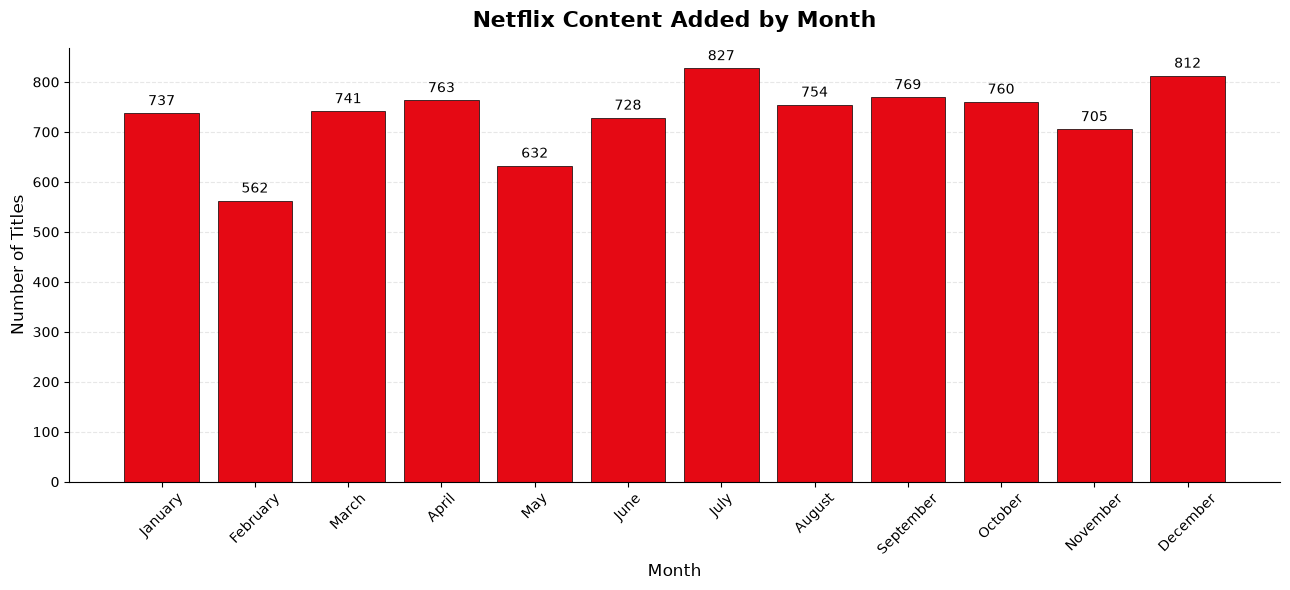

In [126]:
# Netflix Content Added by Month

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Convert date_added into datetime format
df["date_added"] = pd.to_datetime(
    df["date_added"],
    errors="coerce"
)

# Define month order
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

# Calculate monthly content additions
monthly_counts = (
    df["date_added"]
    .dropna()
    .dt.month_name()
    .value_counts()
    .reindex(month_order, fill_value=0)
)

# Create figure
plt.figure(figsize=(13, 6))

# Netflix Red bar chart
bars = plt.bar(
    monthly_counts.index,
    monthly_counts.values,
    color="#E50914",
    edgecolor="black",
    linewidth=0.5
)

# Add values above bars
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 10,
        f"{int(height)}",
        ha="center",
        va="bottom",
        fontsize=10
    )

# Title and labels
plt.title(
    "Netflix Content Added by Month",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Month", fontsize=12)
plt.ylabel("Number of Titles", fontsize=12)

# Styling
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.gca().set_axisbelow(True)

sns.despine()
plt.tight_layout()
plt.show()

In [112]:
# Analyze Year-wise and Month-wise Content Addition

year_month = df.groupby(
    ["year_added", "month_added"]
).size().unstack(fill_value=0)

print("Year-wise Monthly Content Addition:")
display(year_month)

Year-wise Monthly Content Addition:


month_added,1,2,3,4,5,6,7,8,9,10,11,12
year_added,,,,,,,,,,,,
2008,1,1,0,0,0,0,0,0,0,0,0,0
2009,0,0,0,0,1,0,0,0,0,0,1,0
2010,0,0,0,0,0,0,0,0,0,0,1,0
2011,0,0,0,0,1,0,0,0,1,11,0,0
2012,0,1,0,0,0,0,0,0,0,0,1,1
2013,0,0,1,0,0,0,0,1,2,3,2,2
2014,2,2,0,2,0,1,1,1,1,4,4,6
2015,1,4,5,5,6,6,7,2,7,14,4,21
2016,43,15,17,22,13,18,28,33,47,51,44,95


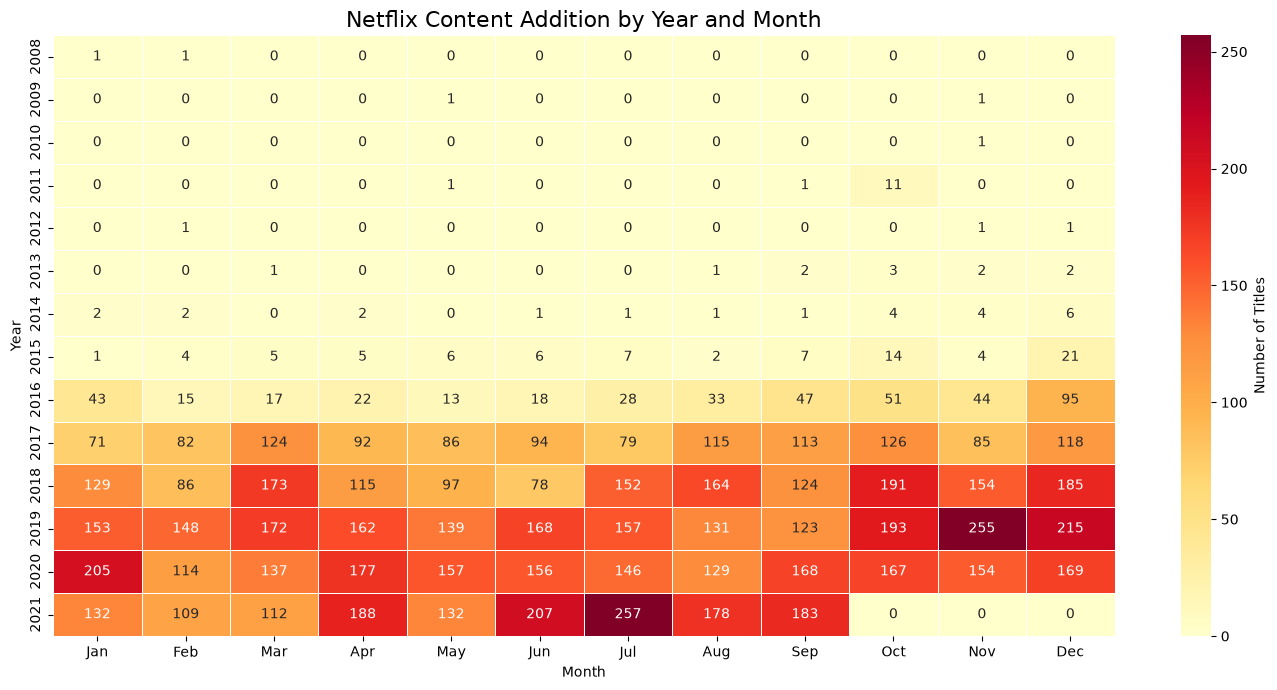

In [113]:
# Create Year-wise Monthly Content Addition Heatmap

plt.figure(figsize=(14, 7))

month_labels = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

sns.heatmap(
    year_month,
    annot=True,
    fmt="d",
    cmap="YlOrRd",
    linewidths=0.5,
    xticklabels=month_labels,
    cbar_kws={"label": "Number of Titles"}
)

plt.title("Netflix Content Addition by Year and Month", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Year")

plt.tight_layout()
plt.show()

## Key Business Insights

Based on the exploratory data analysis of the Netflix dataset, the following insights were identified:

### 1. Content Distribution
- Netflix has 6,126 Movies and 2,664 TV Shows.
- Movies account for approximately 69.7% of the total content.
- TV Shows represent approximately 30.3%.

### 2. Content Addition Trends
- Netflix experienced significant content growth between 2016 and 2020.
- 2019 recorded the highest content addition with 2,016 titles.
- Content addition declined to 1,879 titles in 2020.

### 3. Country-wise Analysis
- The United States is the largest content-producing country with 3,240 titles.
- India ranks second with 1,057 titles.
- The United Kingdom ranks third with 638 titles.

### 4. Ratings Analysis
- TV-MA is the most common rating with 3,205 titles.
- TV-14 is the second most common rating with 2,157 titles.
- This indicates a significant presence of mature and teenage-oriented content.

### 5. Duration Analysis
- The average movie duration is approximately 99.58 minutes.
- Most movies fall within the 90–120 minute category.
- Most TV Shows have only one season (1,791 titles).

### 6. Genre Analysis
- International Movies is the most common genre with 2,752 titles.
- Dramas rank second with 2,426 titles.
- Comedies rank third with 1,674 titles.

### 7. Monthly Content Trends
- July 2021 recorded the highest monthly content addition with 257 titles.
- November 2019 recorded 255 titles.
- Content addition varies across different months and years.

## Conclusion

The Netflix Content Analysis project provided useful insights into the platform's content distribution, production trends, country-wise contributions, ratings, genres, and viewing durations.

The analysis shows that Movies dominate Netflix's content library, with the United States and India being major content contributors. TV-MA is the most common rating, while International Movies and Dramas are among the most popular genres.

The project also highlights significant content growth between 2016 and 2020.

Overall, this exploratory data analysis helped identify important patterns and trends in Netflix's content library using Python, Pandas, Matplotlib, and Seaborn.